What is CIFAR-10?
What does one image look like?
What are the labels?
How many images are in each class?
Is the dataset balanced?

 Imports and dataset location

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from torchvision.datasets import CIFAR10

DATA_DIR = Path("data")
SEED = 42

Download and load CIFAR-10

In [2]:
train_dataset = CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
)

test_dataset = CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
)

class_names = train_dataset.classes

print("Classes:", class_names)
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

100.0%


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 50000
Test images: 10000


Inspect one image and label

Image type: <class 'PIL.Image.Image'>
Image size: (32, 32)
Label number: 6
Label name: frog


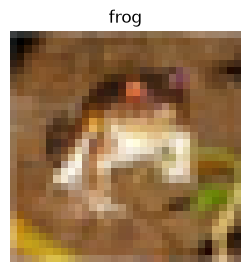

In [3]:
image, label = train_dataset[0]

print("Image type:", type(image))
print("Image size:", image.size)
print("Label number:", label)
print("Label name:", class_names[label])

plt.figure(figsize=(3, 3))
plt.imshow(image)
plt.title(class_names[label])
plt.axis("off")
plt.show()

 Inspect pixel values

In [4]:
image_array = np.array(image)

print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

Array shape: (32, 32, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


Display random examples

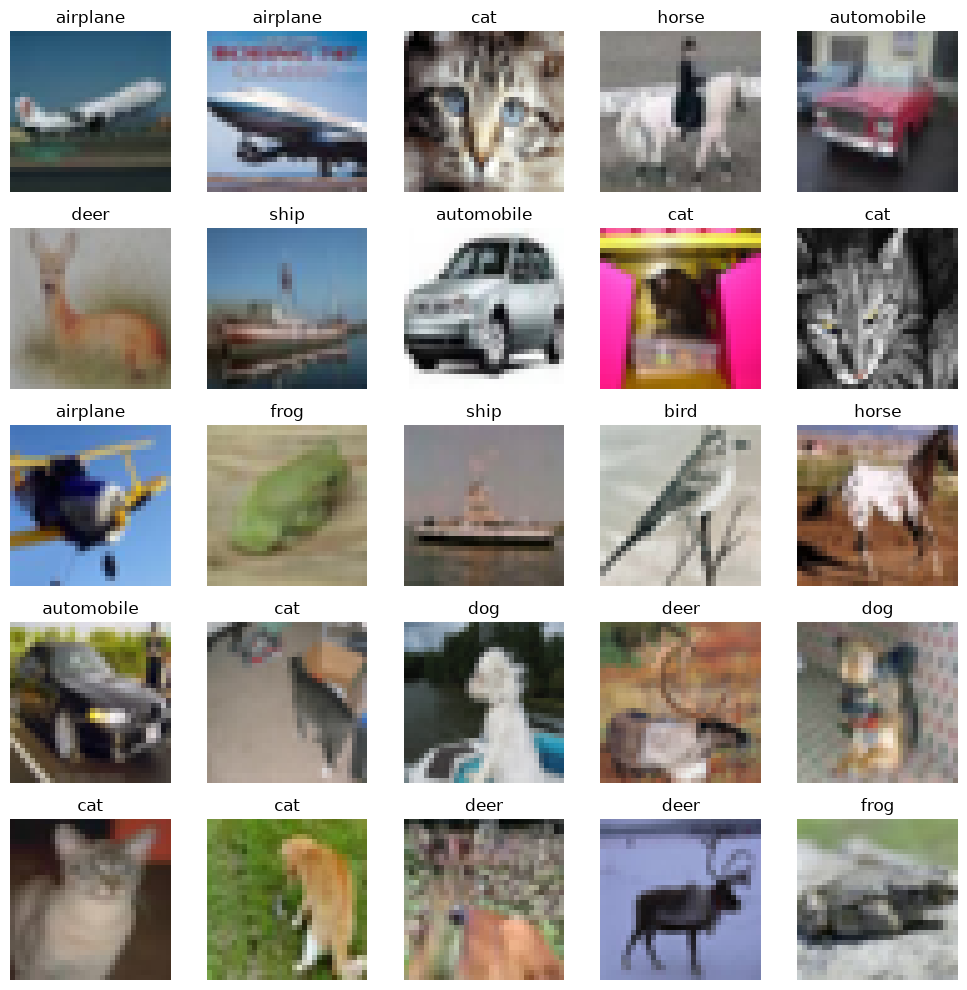

In [7]:
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(train_dataset), size=25, replace=False)

fig, axes = plt.subplots(5, 5, figsize=(10, 10))

for axis, index in zip(axes.flat, sample_indices):
    image, label = train_dataset[index]
    axis.imshow(image)
    axis.set_title(class_names[label])
    axis.axis("off")

plt.tight_layout()
plt.show()

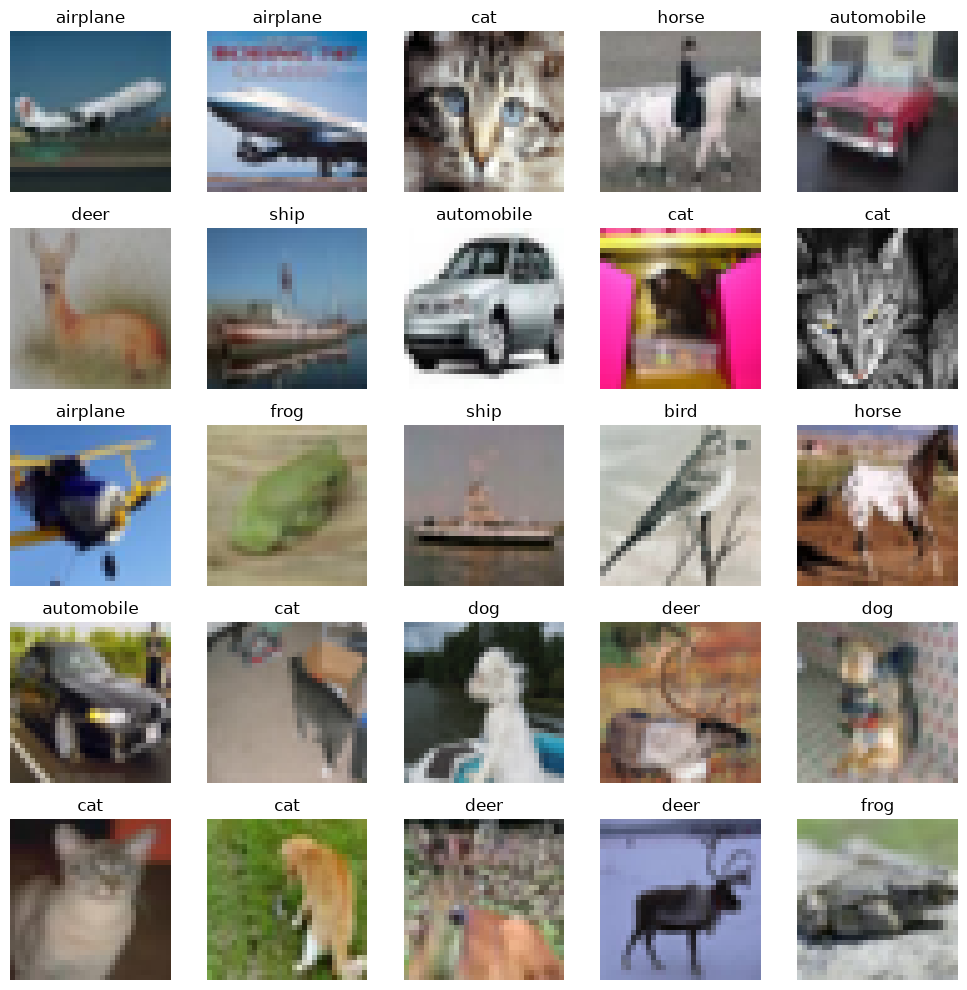

In [ ]:
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(train_dataset), size=25, replace=False)

fig, axes = plt.subplots(5, 5, figsize=(10, 10))

for axis, index in zip(axes.flat, sample_indices):
    image, label = train_dataset[index]
    axis.imshow(image)
    axis.set_title(class_names[label])
    axis.axis("off")

plt.tight_layout()
plt.show()

Count samples in each class

In [8]:
train_counts = Counter(train_dataset.targets)
test_counts = Counter(test_dataset.targets)

print("Training-set counts:")
for class_index, class_name in enumerate(class_names):
    print(f"{class_name:>10}: {train_counts[class_index]}")

print("\nTest-set counts:")
for class_index, class_name in enumerate(class_names):
    print(f"{class_name:>10}: {test_counts[class_index]}")

Training-set counts:
  airplane: 5000
automobile: 5000
      bird: 5000
       cat: 5000
      deer: 5000
       dog: 5000
      frog: 5000
     horse: 5000
      ship: 5000
     truck: 5000

Test-set counts:
  airplane: 1000
automobile: 1000
      bird: 1000
       cat: 1000
      deer: 1000
       dog: 1000
      frog: 1000
     horse: 1000
      ship: 1000
     truck: 1000


7: Visualize class balance

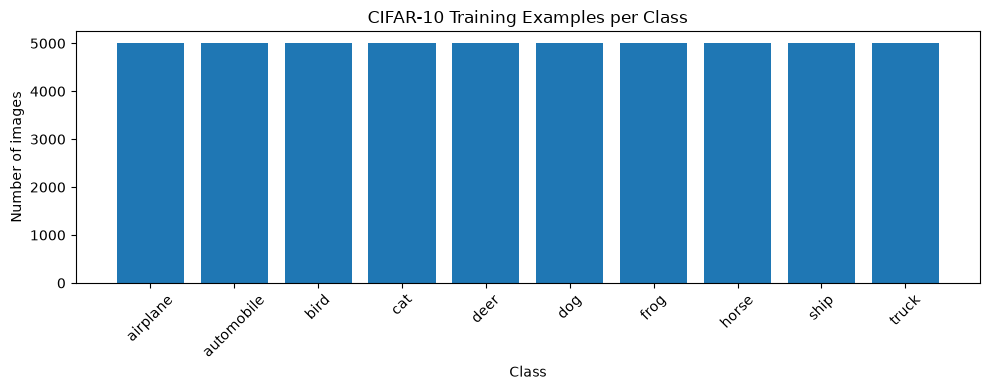

In [9]:
class_counts = [train_counts[class_index] for class_index in range(len(class_names))]

plt.figure(figsize=(10, 4))
plt.bar(class_names, class_counts)
plt.title("CIFAR-10 Training Examples per Class")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()